In [46]:
!pip install shap

In [47]:
import numpy as np
import pandas as pd
import tensorflow as tf
import matplotlib.pyplot as plt
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder

iris = load_iris()
caracteristicas = iris.data
especies = iris.target

display(pd.DataFrame(caracteristicas, columns=iris.feature_names).head())
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report, ConfusionMatrixDisplay

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm)
0,5.1,3.5,1.4,0.2
1,4.9,3.0,1.4,0.2
2,4.7,3.2,1.3,0.2
3,4.6,3.1,1.5,0.2
4,5.0,3.6,1.4,0.2


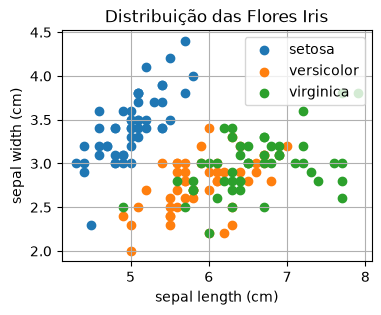

In [48]:
plt.figure(figsize=(4, 3))
for i, nome_alvo in enumerate(iris.target_names):
  plt.scatter(caracteristicas[especies == i, 0], caracteristicas[especies == i, 1], label=nome_alvo)

plt.title("Distribuição das Flores Iris")
plt.xlabel(iris.feature_names[0])
plt.ylabel(iris.feature_names[1])
plt.legend()
plt.grid(True)
plt.show()

In [49]:
encoder = OneHotEncoder(sparse_output=False)
especies_encoded = encoder.fit_transform(especies.reshape(-1, 1))

print('Exemplo de espécies codificadas:')
print('especies_encoded[:5])')

Exemplo de espécies codificadas:
especies_encoded[:5])


In [50]:
caract_treino, caract_teste, esp_treino, esp_teste = train_test_split(
    caracteristicas, especies_encoded, test_size=0.2, random_state=42
)

In [51]:
padronizador = StandardScaler()
caract_treino = padronizador.fit_transform(caract_treino)
caract_teste = padronizador.transform(caract_teste)

In [52]:
model = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(4,)),
    tf.keras.layers.Dense(10, activation='relu'),
    tf.keras.layers.Dense(3, activation='softmax')
])

In [53]:
model.compile(optimizer='adam', loss='categorical_crossentropy', metrics=['accuracy'])

historico = model.fit(caract_treino, esp_treino, epochs=100, batch_size=5, validation_split=0.1)

Epoch 1/100
22/22 ━━━━━━━━━━━━━━━━━━━━ 2s 46ms/step - accuracy: 0.4722 - loss: 1.0159 - val_accuracy: 0.5000 - val_loss: 1.0521
Epoch 2/100
22/22 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accuracy: 0.7130 - loss: 0.8985 - val_accuracy: 0.5000 - val_loss: 1.0018
Epoch 3/100
22/22 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.7593 - loss: 0.8083 - val_accuracy: 0.5833 - val_loss: 0.9599
Epoch 4/100
22/22 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.7778 - loss: 0.7395 - val_accuracy: 0.5833 - val_loss: 0.9244
Epoch 5/100
22/22 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.7870 - loss: 0.6861 - val_accuracy: 0.5833 - val_loss: 0.8930
Epoch 6/100
22/22 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.7870 - loss: 0.6434 - val_accuracy: 0.5833 - val_loss: 0.8645
Epoch 7/100
22/22 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - accuracy: 0.7870 - loss: 0.6080 - val_accuracy: 0.5833 - val_loss: 0.8397
Epoch 8/100
22/22 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - accuracy: 0.7870 - loss: 0.5785 - val_accuracy: 0.5833 

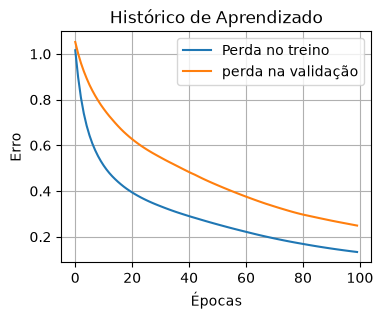

In [54]:
plt.figure(figsize=(4,3))
plt.plot(historico.history['loss'], label='Perda no treino')
plt.plot(historico.history['val_loss'], label='perda na validação')
plt.title('Histórico de Aprendizado')
plt.xlabel('Épocas')
plt.ylabel('Erro')
plt.legend()
plt.grid(True)
plt.show()

In [55]:
preditas = model.predict(caract_teste)
preditas_classes = np.argmax(preditas, axis=1)
especiesc = np.argmax(esp_teste, axis=1)
print(f'{especiesc}\n {preditas_classes}')
print(classification_report(especiesc, preditas_classes))

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 73ms/step
[1 0 2 1 1 0 1 2 1 1 2 0 0 0 0 1 2 1 1 2 0 2 0 2 2 2 2 2 0 0]
 [1 0 2 1 1 0 1 2 1 1 2 0 0 0 0 1 2 1 1 2 0 2 0 2 2 2 2 2 0 0]
              precision    recall  f1-score   support

           0       1.00      1.00      1.00        10
           1       1.00      1.00      1.00         9
           2       1.00      1.00      1.00        11

    accuracy                           1.00        30
   macro avg       1.00      1.00      1.00        30
weighted avg       1.00      1.00      1.00        30



<Figure size 500x400 with 0 Axes>

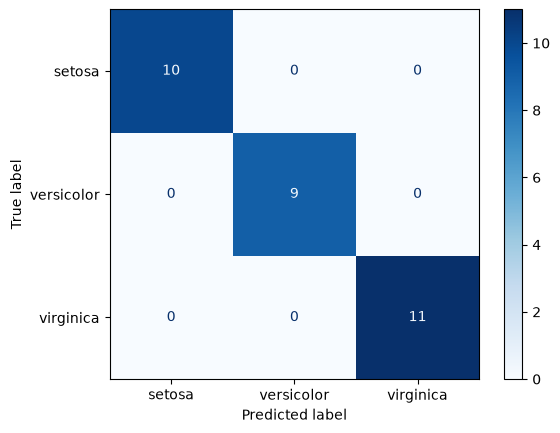

In [56]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
matriz_confusao = confusion_matrix(especiesc, preditas_classes)
plt.figure(figsize=(5,4))
displaymatriz = ConfusionMatrixDisplay(confusion_matrix=matriz_confusao, display_labels=iris.target_names)
displaymatriz.plot(cmap= 'Blues')